# 第 1 课：二维 FFT 看懂图像（约 30 分钟）

目标：知道二维频谱的中心、方向和距离分别代表什么，并能用代码显示图像频谱。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.grid"] = True
# 优先使用常见中文字体；最后的 DejaVu Sans 保证数字和英文正常显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def show_images(images, titles, cmap="gray"):
    """并排显示若干幅图像。"""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    axes = np.atleast_1d(axes)
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 1. 先造几幅可控图像

这样我们确切知道图像中有什么，不需要下载样例图片。


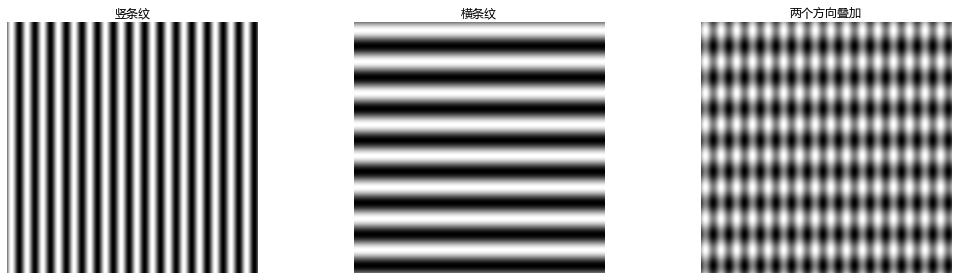

In [2]:
n = 256
y, x = np.mgrid[0:n, 0:n]

vertical_stripes = 0.5 + 0.5 * np.sin(2 * np.pi * x / 16)
horizontal_stripes = 0.5 + 0.5 * np.sin(2 * np.pi * y / 32)
checker = 0.5 + 0.25 * np.sin(2 * np.pi * x / 16) + 0.25 * np.sin(2 * np.pi * y / 32)

show_images([vertical_stripes, horizontal_stripes, checker],
            ["竖条纹", "横条纹", "两个方向叠加"])


## 2. 二维 FFT 与频谱显示

- `fft2`：二维傅里叶变换；
- `fftshift`：把零频（最慢变化）移到画面中心，便于人看；
- `log1p(abs(F))`：频谱强弱跨度很大，取对数后暗处才看得见。

注意：对数只用于**显示**，真正处理仍使用原始复数频谱 `F`。


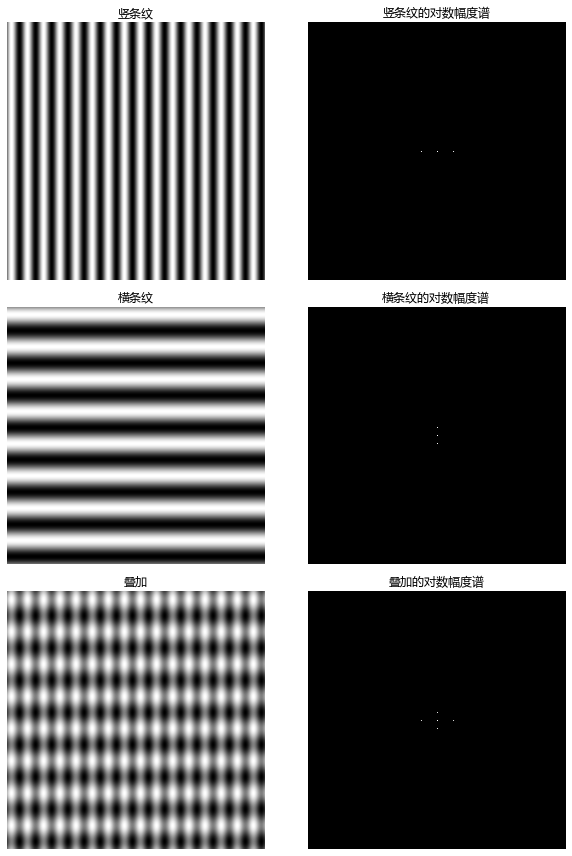

In [3]:
def spectrum_image(image):
    F = np.fft.fft2(image)
    F_centered = np.fft.fftshift(F)
    display = np.log1p(np.abs(F_centered))
    return F_centered, display

fig, axes = plt.subplots(3, 2, figsize=(9, 12))
for row, (image, name) in enumerate([
    (vertical_stripes, "竖条纹"),
    (horizontal_stripes, "横条纹"),
    (checker, "叠加")
]):
    F, spec = spectrum_image(image)
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(name)
    axes[row, 1].imshow(spec)
    axes[row, 1].set_title(name + "的对数幅度谱")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout()
plt.show()


## 读图口诀

1. **中心**代表直流与低频，即平均亮度和缓慢变化；
2. 离中心越远，空间变化越快；
3. 频谱亮点方向与图像变化方向一致，因此竖条纹沿 x 方向变化，亮点出现在频谱水平轴；
4. 实数图像的频谱通常中心对称。

这里很容易混淆：“竖条纹”本身竖着，但亮度是在左右移动时变化，所以频谱亮点左右展开。


## 3. 相位为何不能丢？

幅度大致记录“含有哪些纹理”，相位记录“这些结构放在哪里”。下面交换两幅图的幅度与相位。


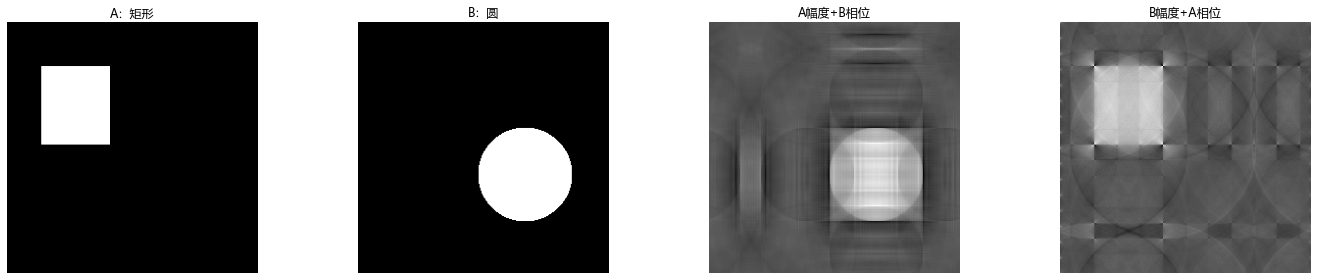

In [4]:
# 两个简单物体，位置和形状不同
image_a = np.zeros((n, n)); image_a[45:125, 35:105] = 1
image_b = np.zeros((n, n));
circle = (x - 170) ** 2 + (y - 155) ** 2 < 48 ** 2
image_b[circle] = 1

Fa, Fb = np.fft.fft2(image_a), np.fft.fft2(image_b)

# A 的幅度 + B 的相位，反之亦然
a_mag_b_phase = np.real(np.fft.ifft2(np.abs(Fa) * np.exp(1j * np.angle(Fb))))
b_mag_a_phase = np.real(np.fft.ifft2(np.abs(Fb) * np.exp(1j * np.angle(Fa))))

show_images([image_a, image_b, a_mag_b_phase, b_mag_a_phase],
            ["A：矩形", "B：圆", "A幅度+B相位", "B幅度+A相位"])


### 工程结论

不要只保存幅度谱再期待完美还原图像。逆变换需要完整复数频谱，它同时包含幅度和相位。


## 小练习

把条纹周期 `/16` 改成 `/8`。频谱亮点应当离中心更远，因为周期更短、变化更快、频率更高。
